<a href="https://colab.research.google.com/github/25041098-mxitd/Covid19-Estadistica-Itd-Unidad-VI/blob/main/Analisis_COVID19_Mexico_2020_2021.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis Estadístico y Probabilístico de Casos COVID-19 en México (2020–2021)

* **Institución:** Instituto Tecnológico de Durango (TecNM)
* **Carrera:** Ingeniería en Sistemas Computacionales
* **Asignatura:** Probabilidad y Estadística
* **Números de Control:** 25041098, 25041016, 25041987
* **Integrantes del Equipo:**
  - Kevon Torres Acosta
  - Aaron Antonio Contreras Herrera
  - Yahir Fernando Vargas Calderón
* **Docente:** Jose Gabriel Rodriguez Rivas
* **Dataset:** `covid2020-2021-codificado.csv`

---

### Objetivo
Analizar los registros de casos COVID-19 en México durante 2020–2021 mediante estadística descriptiva, gráficas exploratorias, cálculo de probabilidad simple y condicional (por comorbilidad y entidad federativa) y ajuste a distribución normal.

## 1. Carga de librerías y datos

Se importan las librerías necesarias y se carga el archivo `covid2020-2021-codificado.csv` desde Google Drive, seleccionando únicamente las 16 columnas de interés y usando tipos categóricos para reducir el consumo de memoria.

In [14]:
from google.colab import drive
from IPython.display import HTML, display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy.stats import norm
import gc
import warnings

warnings.filterwarnings('ignore')

# Fondo negro para todas las gráficas
plt.style.use('dark_background')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['figure.facecolor'] = '#000000'
plt.rcParams['axes.facecolor'] = '#000000'
plt.rcParams['savefig.facecolor'] = '#000000'
plt.rcParams['axes.edgecolor'] = '#444444'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#222222'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['axes.grid'] = True

# Función para renderizar tablas con fondo negro en GitHub
def mostrar_tabla(df):
    html = df.to_html(index=False)
    html = html.replace('<table', '<table style="background-color:#000000; color:#f0f0f0; border-collapse:collapse; width:100%; font-family:sans-serif; font-size:13px;"', 1)
    html = html.replace('<thead', '<thead style="background-color:#161b22; color:#ffffff;"')
    html = html.replace('<th', '<th style="padding:8px 12px; text-align:left; border:1px solid #30363d;"')
    html = html.replace('<td', '<td style="padding:8px 12px; text-align:left; border:1px solid #30363d; background-color:#000000;"')
    display(HTML(html))

# Conectar Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
RUTA_CSV = '/content/drive/MyDrive/covid2020-2021-codificado.csv'

columnas_estudio = [
    'SEXO', 'ENTIDAD_NAC', 'TIPO_PACIENTE', 'FECHA_INGRESO',
    'EDAD', 'EMBARAZO', 'INDIGENA',
    'DIABETES', 'EPOC', 'ASMA', 'HIPERTENSION',
    'CARDIOVASCULAR', 'OBESIDAD', 'RENAL_CRONICA', 'TABAQUISMO',
    'RESULTADO_ANTIGENO'
]

dtypes_optimizados = {
    'SEXO': 'category',
    'ENTIDAD_NAC': 'category',
    'TIPO_PACIENTE': 'category',
    'EDAD': 'float32',
    'EMBARAZO': 'category',
    'INDIGENA': 'category',
    'DIABETES': 'category',
    'EPOC': 'category',
    'ASMA': 'category',
    'HIPERTENSION': 'category',
    'CARDIOVASCULAR': 'category',
    'OBESIDAD': 'category',
    'RENAL_CRONICA': 'category',
    'TABAQUISMO': 'category',
    'RESULTADO_ANTIGENO': 'category'
}

print("Cargando dataset...")
df = pd.read_csv(
    RUTA_CSV,
    usecols=columnas_estudio,
    dtype=dtypes_optimizados,
    encoding='utf-8'
)

df['FECHA_INGRESO'] = pd.to_datetime(df['FECHA_INGRESO'], format='%d/%m/%Y', errors='coerce')
gc.collect()

memoria_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"Carga completada. Registros: {len(df):,} | Columnas: {df.shape[1]} | RAM: {memoria_mb:.2f} MB")

Cargando dataset...
Carga completada. Registros: 12,634,194 | Columnas: 16 | RAM: 313.28 MB


## 2. Estadística Descriptiva

Frecuencias absolutas y porcentajes de las variables demográficas y clínicas principales, junto con las medidas de tendencia central y dispersión de la edad.

In [16]:
total_registros = len(df)

def tabla_frecuencias(serie, nombre_var):
    conteos = serie.value_counts(dropna=False)
    porcentajes = (conteos / total_registros) * 100
    return pd.DataFrame({
        'Variable': nombre_var,
        'Categoría': conteos.index.astype(str),
        'Frecuencia Absoluta': conteos.values,
        'Porcentaje (%)': np.round(porcentajes.values, 2)
    })

t_resultado = tabla_frecuencias(df['RESULTADO_ANTIGENO'], 'Resultado Antígeno')
t_paciente = tabla_frecuencias(df['TIPO_PACIENTE'], 'Tipo de Paciente')
t_sexo = tabla_frecuencias(df['SEXO'], 'Sexo')
t_embarazo = tabla_frecuencias(df['EMBARAZO'], 'Embarazo (Total)')
t_indigena = tabla_frecuencias(df['INDIGENA'], 'Indígena')

tabla_general = pd.concat([t_resultado, t_paciente, t_sexo, t_embarazo, t_indigena], ignore_index=True)
tabla_general['Frecuencia Absoluta'] = tabla_general['Frecuencia Absoluta'].map('{:,}'.format)
tabla_general['Porcentaje (%)'] = tabla_general['Porcentaje (%)'].map('{:.2f}%'.format)

print("=== RESUMEN DESCRIPTIVO GENERAL ===")
mostrar_tabla(tabla_general)

mujeres_df = df[df['SEXO'] == 'Femenino']
emb_mujeres = mujeres_df['EMBARAZO'].value_counts()
print(f"\n=== DESGLOSE DE EMBARAZO EN POBLACIÓN FEMENINA (Total mujeres: {len(mujeres_df):,}) ===")
for cat, val in emb_mujeres.items():
    print(f"  - {cat}: {val:,} ({val / len(mujeres_df) * 100:.2f}%)")

del mujeres_df
gc.collect()

# Estadísticos de edad (rango 0 a 120 años)
edad_valida = df['EDAD'][(df['EDAD'] >= 0) & (df['EDAD'] <= 120)]
stats_edad = pd.DataFrame({
    'Métrica': ['Registros válidos', 'Media', 'Desviación Estándar', 'Mínimo', 'Percentil 25 (Q1)', 'Mediana (Q2)', 'Percentil 75 (Q3)', 'Rango Intercuartílico (IQR)', 'Máximo'],
    'Valor': [
        f"{len(edad_valida):,}",
        f"{edad_valida.mean():.2f} años",
        f"{edad_valida.std():.2f} años",
        f"{edad_valida.min():.0f} años",
        f"{edad_valida.quantile(0.25):.0f} años",
        f"{edad_valida.median():.0f} años",
        f"{edad_valida.quantile(0.75):.0f} años",
        f"{(edad_valida.quantile(0.75) - edad_valida.quantile(0.25)):.0f} años",
        f"{edad_valida.max():.0f} años"
    ]
})
print("\n=== ESTADÍSTICOS DESCRIPTIVOS DE EDAD ===")
mostrar_tabla(stats_edad)

=== RESUMEN DESCRIPTIVO GENERAL ===


Variable,Categoría,Frecuencia Absoluta,Porcentaje (%)
Resultado Antígeno,Negativo,"5,853,547",46.33%
Resultado Antígeno,Pendiente,"5,005,939",39.62%
Resultado Antígeno,Positivo,"1,774,708",14.05%
Tipo de Paciente,Ambulatorio,"11,543,303",91.37%
Tipo de Paciente,Hospitalizado,"1,090,891",8.63%
Sexo,Femenino,"6,648,738",52.62%
Sexo,Masculino,"5,985,456",47.38%
Embarazo (Total),No,"6,483,614",51.32%
Embarazo (Total),No aplica,"5,985,456",47.38%
Embarazo (Total),Si,"122,583",0.97%



=== DESGLOSE DE EMBARAZO EN POBLACIÓN FEMENINA (Total mujeres: 6,648,738) ===
  - No: 6,483,614 (97.52%)
  - Si: 122,583 (1.84%)
  - Se ignora: 42,529 (0.64%)
  - No especificado: 12 (0.00%)
  - No aplica: 0 (0.00%)

=== ESTADÍSTICOS DESCRIPTIVOS DE EDAD ===


Métrica,Valor
Registros válidos,"12,630,604"
Media,38.70 años
Desviación Estándar,16.97 años
Mínimo,0 años
Percentil 25 (Q1),26 años
Mediana (Q2),37 años
Percentil 75 (Q3),50 años
Rango Intercuartílico (IQR),24 años
Máximo,120 años


## 3. Visualizaciones Estadísticas del Dataset

Se construyen **6 visualizaciones** para explorar la distribución geográfica, demográfica, temporal y clínica de los registros:
1. **Gráfica 1:** Barras horizontales de registros totales y casos positivos por entidad federativa (`ENTIDAD_NAC`).
2. **Gráfica 2:** Histograma de distribución de `EDAD` comparando población general y casos positivos.
3. **Gráfica 3:** Serie de tiempo mensual por fecha de ingreso (`FECHA_INGRESO`).
4. **Gráfica 4:** Barras apiladas por `SEXO` y `RESULTADO_ANTIGENO`.
5. **Gráfica 5:** Gráfico circular (dona) de `TIPO_PACIENTE` (`Ambulatorio` vs. `Hospitalizado`).
6. **Gráfica 6:** Barras horizontales comparativas de prevalencia por comorbilidad.

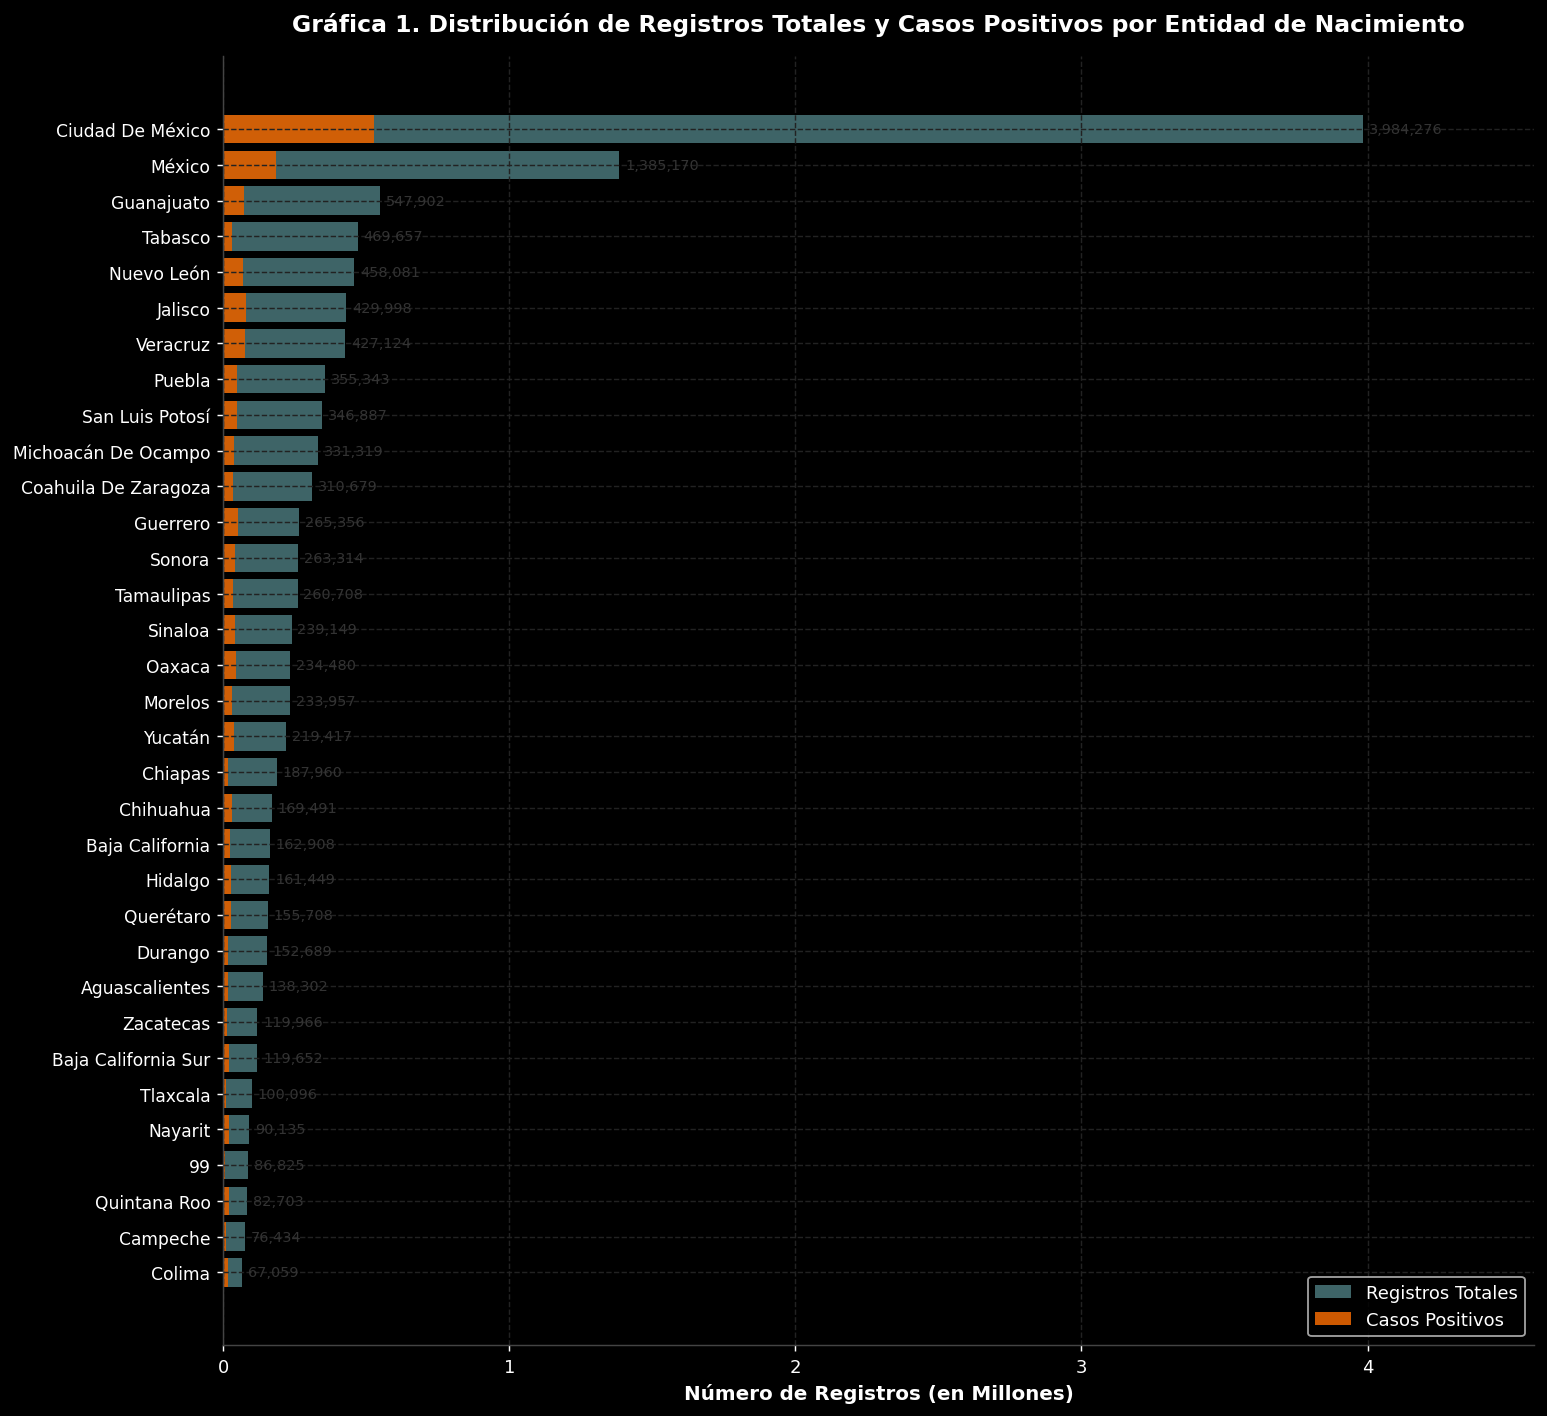

In [17]:
# --- GRÁFICA 1: Barras horizontales por Entidad Federativa ---
conteo_entidad = df.groupby(['ENTIDAD_NAC', 'RESULTADO_ANTIGENO'], observed=False).size().unstack(fill_value=0)
conteo_entidad['Total'] = conteo_entidad.sum(axis=1)
conteo_entidad = conteo_entidad.sort_values('Total', ascending=True)

fig, ax = plt.subplots(figsize=(12, 11))
y_pos = np.arange(len(conteo_entidad))

ax.barh(y_pos, conteo_entidad['Total'] / 1e6, color='#4A777A', alpha=0.85, label='Registros Totales')
if 'Positivo' in conteo_entidad.columns:
    ax.barh(y_pos, conteo_entidad['Positivo'] / 1e6, color='#D95F02', alpha=0.95, label='Casos Positivos')

ax.set_yticks(y_pos)
ax.set_yticklabels(conteo_entidad.index, fontsize=9.5)
ax.set_xlabel('Número de Registros (en Millones)', fontsize=11, fontweight='bold')
ax.set_title('Gráfica 1. Distribución de Registros Totales y Casos Positivos por Entidad de Nacimiento', fontsize=13, fontweight='bold', pad=14)
ax.legend(loc='lower right', frameon=True, fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for i, total in enumerate(conteo_entidad['Total']):
    ax.text((total / 1e6) + 0.02, i, f"{total:,}", va='center', fontsize=8, color='#333333')

plt.xlim(0, (conteo_entidad['Total'].max() / 1e6) * 1.15)
plt.tight_layout()
plt.show()

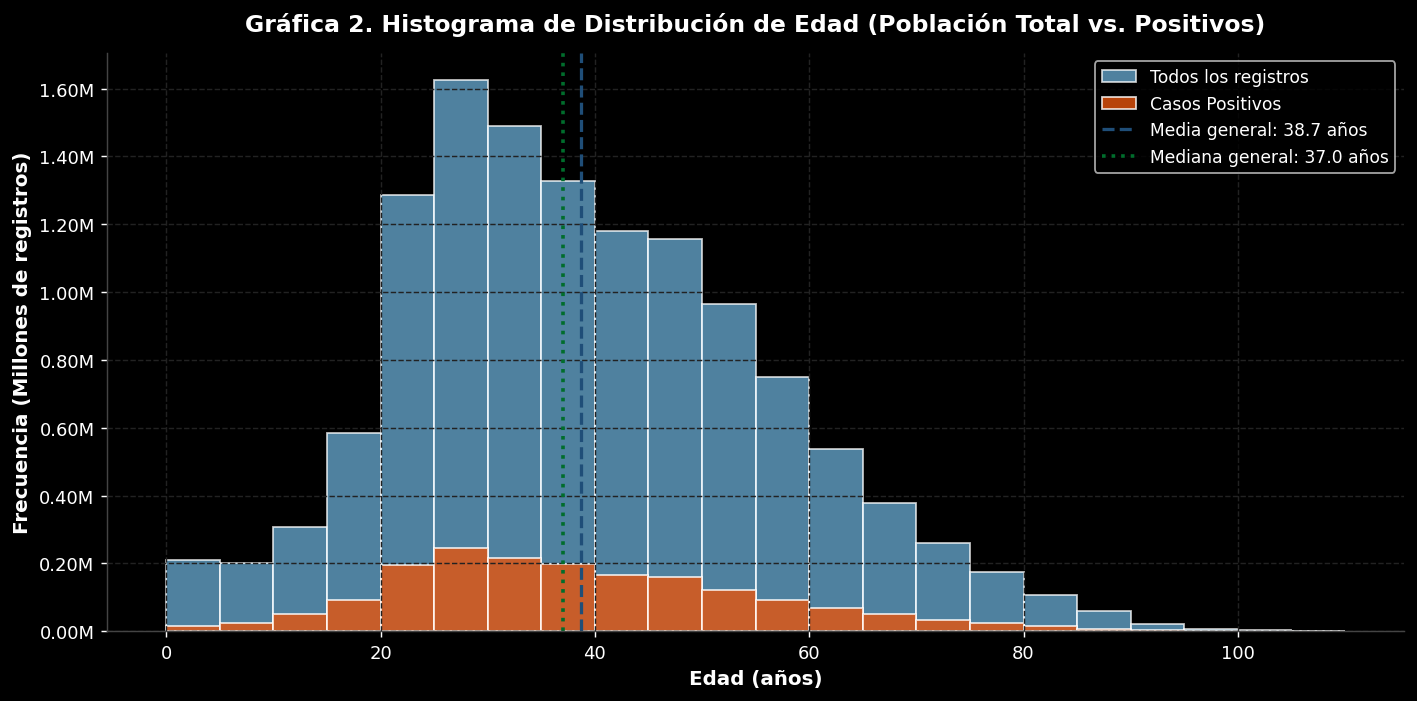

3798

In [18]:
# --- GRÁFICA 2: Histograma de distribución de Edad ---
edades_totales = df['EDAD'][(df['EDAD'] >= 0) & (df['EDAD'] <= 110)].dropna()
edades_positivas = df.loc[df['RESULTADO_ANTIGENO'] == 'Positivo', 'EDAD']
edades_positivas = edades_positivas[(edades_positivas >= 0) & (edades_positivas <= 110)].dropna()

fig, ax = plt.subplots(figsize=(11, 5.5))
bins = np.arange(0, 112, 5)

ax.hist(edades_totales, bins=bins, color='#6BAED6', edgecolor='white', alpha=0.75, label='Todos los registros')
ax.hist(edades_positivas, bins=bins, color='#E6550D', edgecolor='white', alpha=0.80, label='Casos Positivos')

media_edad = edades_totales.mean()
mediana_edad = edades_totales.median()
ax.axvline(media_edad, color='#1F4E78', linestyle='--', linewidth=1.8, label=f'Media general: {media_edad:.1f} años')
ax.axvline(mediana_edad, color='#006D2C', linestyle=':', linewidth=2.0, label=f'Mediana general: {mediana_edad:.1f} años')

ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.2f}M'))
ax.set_xlabel('Edad (años)', fontsize=11, fontweight='bold')
ax.set_ylabel('Frecuencia (Millones de registros)', fontsize=11, fontweight='bold')
ax.set_title('Gráfica 2. Histograma de Distribución de Edad (Población Total vs. Positivos)', fontsize=13, fontweight='bold', pad=12)
ax.legend(frameon=True, fontsize=9.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

del edades_totales, edades_positivas
gc.collect()

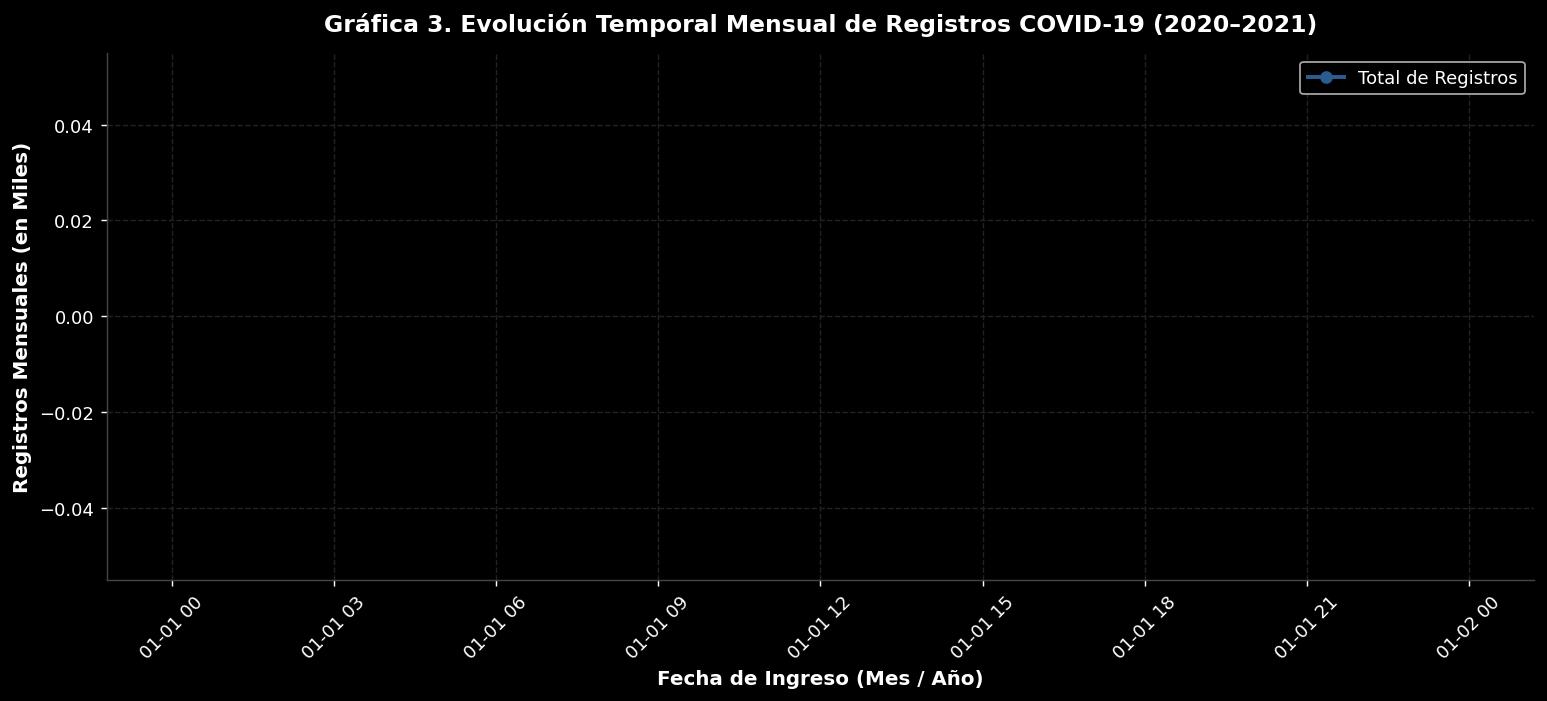

6363

In [19]:
# --- GRÁFICA 3: Serie de tiempo por Fecha de Ingreso ---
df_tiempo = df[['FECHA_INGRESO', 'RESULTADO_ANTIGENO']].dropna(subset=['FECHA_INGRESO']).copy()
df_tiempo['MES_INGRESO'] = df_tiempo['FECHA_INGRESO'].dt.to_period('M').dt.to_timestamp()

serie_mensual = df_tiempo.groupby(['MES_INGRESO', 'RESULTADO_ANTIGENO'], observed=False).size().unstack(fill_value=0)
serie_mensual['Total'] = serie_mensual.sum(axis=1)
serie_mensual = serie_mensual[(serie_mensual.index >= '2020-01-01') & (serie_mensual.index <= '2021-12-31')]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(serie_mensual.index, serie_mensual['Total'] / 1e3, marker='o', linewidth=2.2, color='#2B5C8F', label='Total de Registros')
if 'Positivo' in serie_mensual.columns:
    ax.plot(serie_mensual.index, serie_mensual['Positivo'] / 1e3, marker='s', linewidth=2.2, color='#D95F02', label='Casos Positivos')
if 'Negativo' in serie_mensual.columns:
    ax.plot(serie_mensual.index, serie_mensual['Negativo'] / 1e3, marker='^', linewidth=1.8, linestyle='--', color='#1B9E77', label='Casos Negativos')

ax.set_xlabel('Fecha de Ingreso (Mes / Año)', fontsize=11, fontweight='bold')
ax.set_ylabel('Registros Mensuales (en Miles)', fontsize=11, fontweight='bold')
ax.set_title('Gráfica 3. Evolución Temporal Mensual de Registros COVID-19 (2020–2021)', fontsize=13, fontweight='bold', pad=12)
ax.legend(frameon=True, fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

del df_tiempo
gc.collect()

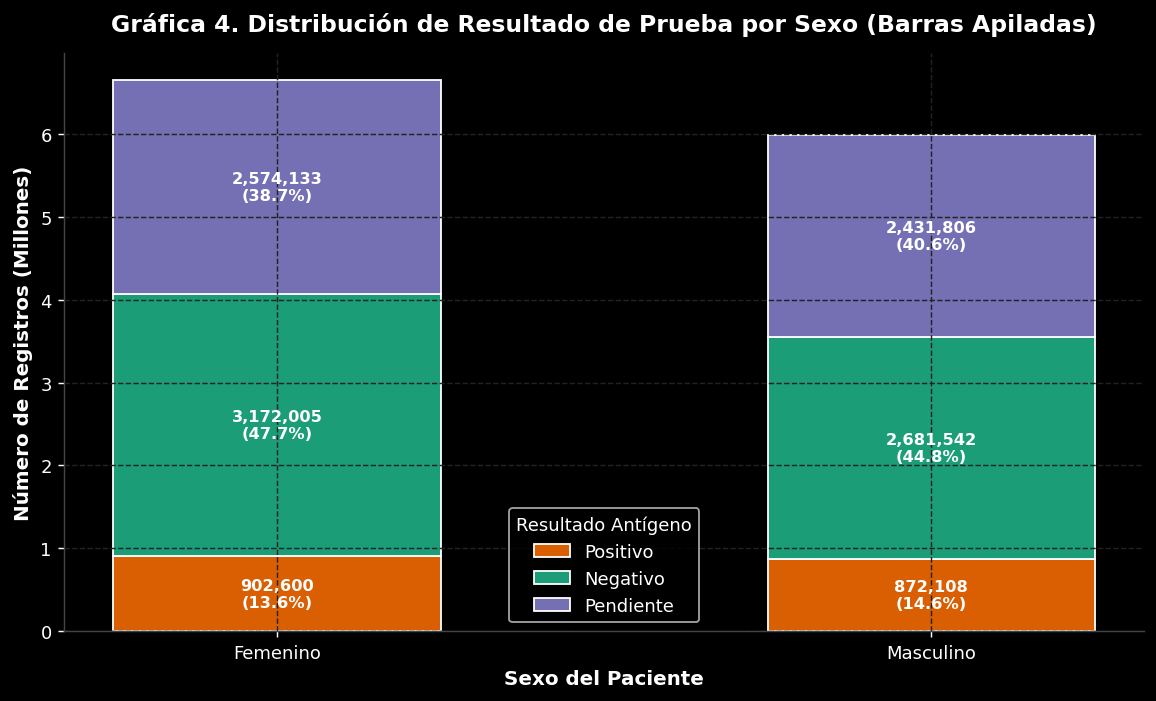

In [20]:
# --- GRÁFICA 4: Barras apiladas por Sexo y Resultado de Antígeno ---
sexo_res = pd.crosstab(df['SEXO'], df['RESULTADO_ANTIGENO'])
sexo_res_pct = sexo_res.div(sexo_res.sum(axis=1), axis=0) * 100

colores_res = {'Positivo': '#D95F02', 'Negativo': '#1B9E77', 'Pendiente': '#7570B3'}
cols_ordenadas = [c for c in ['Positivo', 'Negativo', 'Pendiente'] if c in sexo_res.columns]

fig, ax = plt.subplots(figsize=(9, 5.5))
bottom = np.zeros(len(sexo_res))

for col in cols_ordenadas:
    vals = sexo_res[col].values / 1e6
    pcts = sexo_res_pct[col].values
    bars = ax.bar(sexo_res.index, vals, bottom=bottom, width=0.5, label=col, color=colores_res.get(col, '#888888'), edgecolor='white')
    for idx, bar in enumerate(bars):
        if vals[idx] > 0.25:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bottom[idx] + vals[idx] / 2,
                f"{sexo_res[col].iloc[idx]:,}\n({pcts[idx]:.1f}%)",
                ha='center', va='center', color='white', fontweight='bold', fontsize=9
            )
    bottom += vals

ax.set_xlabel('Sexo del Paciente', fontsize=11, fontweight='bold')
ax.set_ylabel('Número de Registros (Millones)', fontsize=11, fontweight='bold')
ax.set_title('Gráfica 4. Distribución de Resultado de Prueba por Sexo (Barras Apiladas)', fontsize=13, fontweight='bold', pad=12)
ax.legend(title='Resultado Antígeno', frameon=True, fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

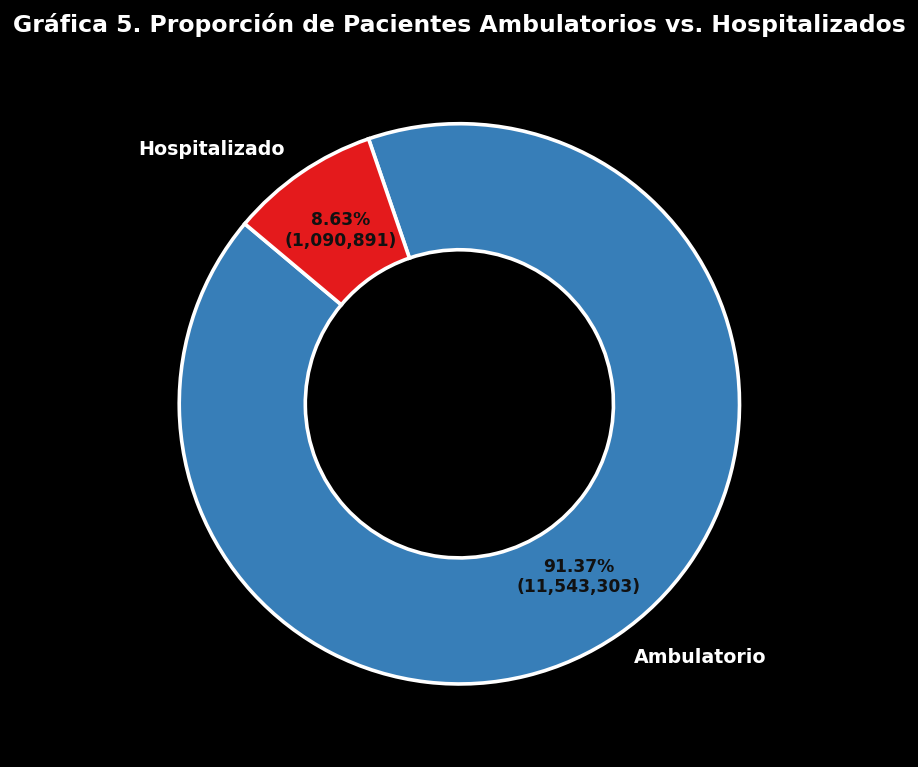

In [21]:
# --- GRÁFICA 5: Gráfico circular (Dona) de Tipo de Paciente ---
conteo_tipo = df['TIPO_PACIENTE'].value_counts()

fig, ax = plt.subplots(figsize=(7.5, 6))
colores_tipo = ['#377EB8', '#E41A1C']
wedges, texts, autotexts = ax.pie(
    conteo_tipo.values,
    labels=conteo_tipo.index,
    autopct=lambda pct: f"{pct:.2f}%\n({int(round(pct/100.*conteo_tipo.sum())):,})",
    startangle=140,
    colors=colores_tipo[:len(conteo_tipo)],
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=10.5, fontweight='bold')
)

for autotext in autotexts:
    autotext.set_color('#111111')
    autotext.set_fontsize(9.5)

ax.set_title('Gráfica 5. Proporción de Pacientes Ambulatorios vs. Hospitalizados', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

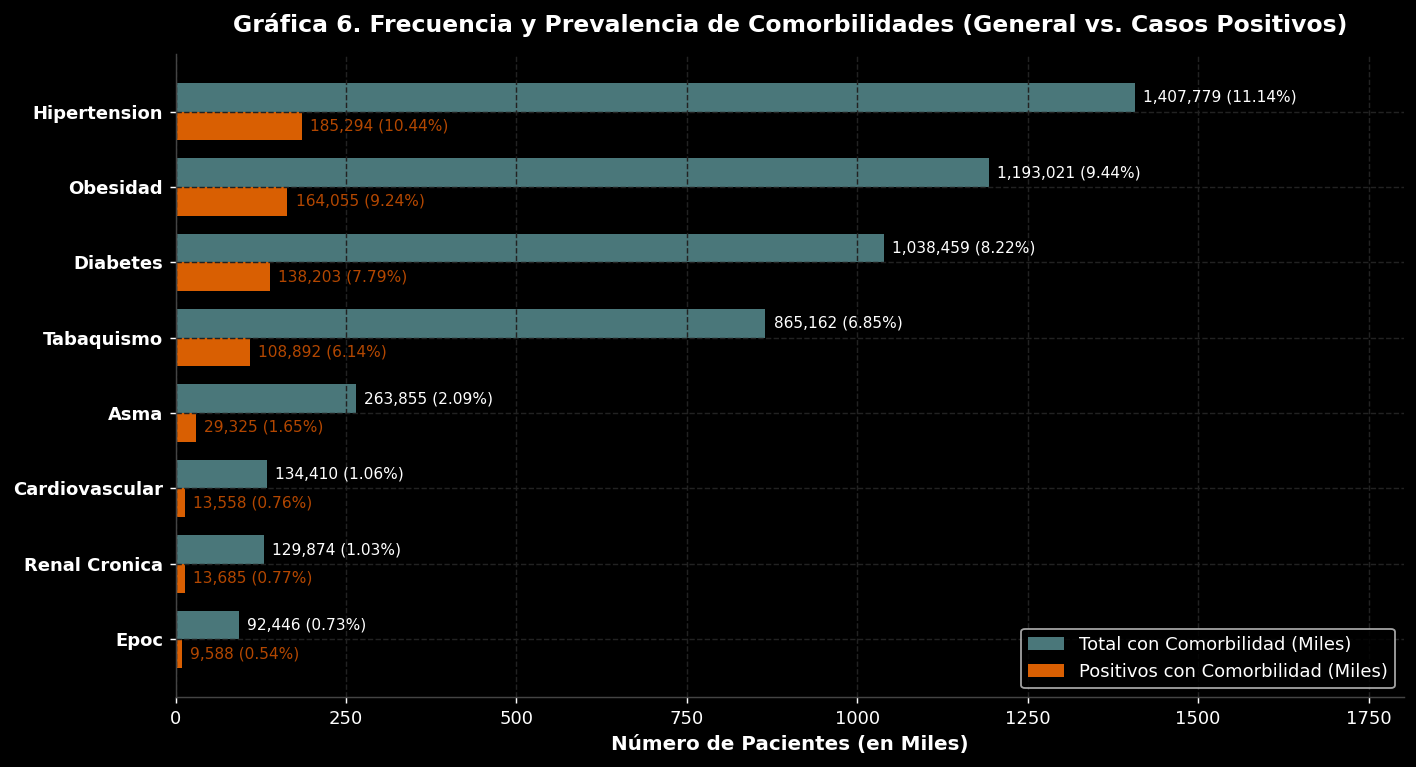

In [22]:
# --- GRÁFICA 6: Barras comparativas por Comorbilidad ---
comorbilidades_lista = [
    'DIABETES', 'HIPERTENSION', 'OBESIDAD', 'TABAQUISMO',
    'ASMA', 'CARDIOVASCULAR', 'EPOC', 'RENAL_CRONICA'
]

datos_comorb = []
es_positivo = (df['RESULTADO_ANTIGENO'] == 'Positivo')
total_pos = es_positivo.sum()

for col in comorbilidades_lista:
    tiene_comorb = (df[col] == 'Si')
    n_total_si = tiene_comorb.sum()
    n_pos_si = (tiene_comorb & es_positivo).sum()
    datos_comorb.append({
        'Comorbilidad': col.replace('_', ' ').title(),
        'Total_Si': n_total_si,
        'Positivos_Si': n_pos_si,
        'Pct_General': (n_total_si / total_registros) * 100,
        'Pct_En_Positivos': (n_pos_si / total_pos) * 100 if total_pos > 0 else 0
    })

df_comorb_plot = pd.DataFrame(datos_comorb).sort_values('Total_Si', ascending=True)

fig, ax = plt.subplots(figsize=(11, 6))
y_idx = np.arange(len(df_comorb_plot))
altura = 0.38

ax.barh(y_idx + altura/2, df_comorb_plot['Total_Si'] / 1e3, height=altura, color='#4A777A', label='Total con Comorbilidad (Miles)')
ax.barh(y_idx - altura/2, df_comorb_plot['Positivos_Si'] / 1e3, height=altura, color='#D95F02', label='Positivos con Comorbilidad (Miles)')

for i, row in enumerate(df_comorb_plot.itertuples()):
    ax.text((row.Total_Si / 1e3) + 12, i + altura/2, f"{row.Total_Si:,} ({row.Pct_General:.2f}%)", va='center', fontsize=8.5)
    ax.text((row.Positivos_Si / 1e3) + 12, i - altura/2, f"{row.Positivos_Si:,} ({row.Pct_En_Positivos:.2f}%)", va='center', fontsize=8.5, color='#B34700')

ax.set_yticks(y_idx)
ax.set_yticklabels(df_comorb_plot['Comorbilidad'], fontsize=10, fontweight='bold')
ax.set_xlabel('Número de Pacientes (en Miles)', fontsize=11, fontweight='bold')
ax.set_title('Gráfica 6. Frecuencia y Prevalencia de Comorbilidades (General vs. Casos Positivos)', fontsize=13, fontweight='bold', pad=12)
ax.legend(loc='lower right', frameon=True, fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xlim(0, (df_comorb_plot['Total_Si'].max() / 1e3) * 1.28)

plt.tight_layout()
plt.show()

## 4. Cálculo de Probabilidad Simple y Probabilidad Condicional por Comorbilidad y Entidad

> **Nota sobre columnas del dataset:** En `covid2020-2021-codificado.csv` se encuentran registradas **8 comorbilidades** (`DIABETES`, `HIPERTENSION`, `OBESIDAD`, `EPOC`, `ASMA`, `CARDIOVASCULAR`, `RENAL_CRONICA` y `TABAQUISMO`). La variable *Inmunosupresión* no está incluida en esta versión codificada del CSV, por lo que el análisis abarca íntegramente las 8 comorbilidades disponibles.

### Definiciones Probabilísticas Aplicadas
Para cada comorbilidad $C_i$ (excluyendo registros marcados como `'Se ignora'` en el denominador válido de cada condición):
1. **Probabilidad Simple de Comorbilidad:**
   $$P(C_i) = \frac{n(C_i = \text{Si})}{n(C_i \in \{\text{Si}, \text{No}\})}$$
2. **Probabilidad Condicional de Resultado Positivo dado que el paciente padece $C_i$:**
   $$P(\text{Positivo} \mid C_i) = \frac{n(\text{Positivo} \cap C_i = \text{Si})}{n(C_i = \text{Si})}$$
3. **Probabilidad Condicional de padecer $C_i$ dado que el resultado fue Positivo:**
   $$P(C_i \mid \text{Positivo}) = \frac{n(\text{Positivo} \cap C_i = \text{Si})}{n(\text{Positivo} \cap C_i \in \{\text{Si}, \text{No}\})}$$

In [23]:
# --- 4A. PROBABILIDADES SIMPLES Y CONDICIONALES A NIVEL NACIONAL ---
resultados_prob_nacional = []

for col in comorbilidades_lista:
    validos = df[col].isin(['Si', 'No'])
    es_si = (df[col] == 'Si')
    es_pos = (df['RESULTADO_ANTIGENO'] == 'Positivo')

    n_validos = validos.sum()
    n_si = es_si.sum()
    n_pos_y_si = (es_si & es_pos).sum()
    n_pos_validos = (validos & es_pos).sum()

    p_simple = n_si / n_validos
    p_pos_dado_c = n_pos_y_si / n_si if n_si > 0 else 0
    p_c_dado_pos = n_pos_y_si / n_pos_validos if n_pos_validos > 0 else 0

    resultados_prob_nacional.append({
        'Comorbilidad': col.replace('_', ' ').title(),
        'N Válidos (Si/No)': n_validos,
        'Casos con Comorbilidad (Si)': n_si,
        'Positivos con Comorbilidad': n_pos_y_si,
        'P(Comorbilidad) [Simple]': p_simple,
        'P(Positivo | Comorbilidad) [Condicional]': p_pos_dado_c,
        'P(Comorbilidad | Positivo) [Condicional]': p_c_dado_pos
    })

df_prob_nacional = pd.DataFrame(resultados_prob_nacional).sort_values('P(Comorbilidad) [Simple]', ascending=False)

print("=== TABLA 4A: PROBABILIDAD SIMPLE Y CONDICIONAL POR COMORBILIDAD (NIVEL NACIONAL) ===")
display(df_prob_nacional.style.format({
    'N Válidos (Si/No)': '{:,}',
    'Casos con Comorbilidad (Si)': '{:,}',
    'Positivos con Comorbilidad': '{:,}',
    'P(Comorbilidad) [Simple]': '{:.4%}',
    'P(Positivo | Comorbilidad) [Condicional]': '{:.4%}',
    'P(Comorbilidad | Positivo) [Condicional]': '{:.4%}'
}))

=== TABLA 4A: PROBABILIDAD SIMPLE Y CONDICIONAL POR COMORBILIDAD (NIVEL NACIONAL) ===


,Comorbilidad,N Válidos (Si/No),Casos con Comorbilidad (Si),Positivos con Comorbilidad,P(Comorbilidad) [Simple],P(Positivo | Comorbilidad) [Condicional],P(Comorbilidad | Positivo) [Condicional]
1,Hipertension,"12,565,590","1,407,779","185,294",11.2034%,13.1622%,10.4573%
2,Obesidad,"12,566,735","1,193,021","164,055",9.4935%,13.7512%,9.2576%
0,Diabetes,"12,563,927","1,038,459","138,203",8.2654%,13.3085%,7.8005%
3,Tabaquismo,"12,564,870","865,162","108,892",6.8856%,12.5863%,6.1456%
4,Asma,"12,566,157","263,855","29,325",2.0997%,11.1141%,1.6549%
5,Cardiovascular,"12,565,833","134,410","13,558",1.0696%,10.0870%,0.7651%
7,Renal Cronica,"12,566,106","129,874","13,685",1.0335%,10.5371%,0.7723%
6,Epoc,"12,565,812","92,446","9,588",0.7357%,10.3715%,0.5411%


In [24]:
# --- 4B. PROBABILIDADES POR ENTIDAD FEDERATIVA Y COMORBILIDAD ---
registros_estado = []

df['_IS_POS'] = (df['RESULTADO_ANTIGENO'] == 'Positivo').astype('int8')

for col in comorbilidades_lista:
    sub = df[df[col].isin(['Si', 'No'])][['ENTIDAD_NAC', col, '_IS_POS']].copy()
    sub['_IS_SI'] = (sub[col] == 'Si').astype('int8')
    sub['_SI_Y_POS'] = (sub['_IS_SI'] & sub['_IS_POS']).astype('int8')

    grp = sub.groupby('ENTIDAD_NAC', observed=False).agg(
        N_Validos=('_IS_SI', 'count'),
        N_Comorb=('_IS_SI', 'sum'),
        N_Pos_Comorb=('_SI_Y_POS', 'sum')
    ).reset_index()

    grp['Comorbilidad'] = col
    grp['P_Simple_Comorb'] = grp['N_Comorb'] / grp['N_Validos']
    grp['P_Cond_Pos_dado_Comorb'] = np.where(grp['N_Comorb'] > 0, grp['N_Pos_Comorb'] / grp['N_Comorb'], 0.0)
    registros_estado.append(grp)

df.drop(columns=['_IS_POS'], inplace=True)
gc.collect()

df_prob_estados = pd.concat(registros_estado, ignore_index=True)

# Matriz pivoteada de Probabilidad Simple P(Comorbilidad) por Entidad (%)
matriz_p_simple = df_prob_estados.pivot(index='ENTIDAD_NAC', columns='Comorbilidad', values='P_Simple_Comorb') * 100
matriz_p_simple = matriz_p_simple[comorbilidades_lista]

# Matriz pivoteada de Probabilidad Condicional P(Positivo | Comorbilidad) por Entidad (%)
matriz_p_cond = df_prob_estados.pivot(index='ENTIDAD_NAC', columns='Comorbilidad', values='P_Cond_Pos_dado_Comorb') * 100
matriz_p_cond = matriz_p_cond[comorbilidades_lista]

print("=== TABLA 4B-1: PROBABILIDAD SIMPLE P(Comorbilidad) POR ENTIDAD FEDERATIVA (%) ===")
display(matriz_p_simple.style.format('{:.2f}%').background_gradient(cmap='YlGnBu', axis=None))

print("\n=== TABLA 4B-2: PROBABILIDAD CONDICIONAL P(Positivo | Comorbilidad) POR ENTIDAD FEDERATIVA (%) ===")
display(matriz_p_cond.style.format('{:.2f}%').background_gradient(cmap='OrRd', axis=None))

=== TABLA 4B-1: PROBABILIDAD SIMPLE P(Comorbilidad) POR ENTIDAD FEDERATIVA (%) ===


Comorbilidad,DIABETES,HIPERTENSION,OBESIDAD,TABAQUISMO,ASMA,CARDIOVASCULAR,EPOC,RENAL_CRONICA
ENTIDAD_NAC,,,,,,,,
99,2.44%,5.12%,4.17%,4.86%,2.69%,0.87%,0.39%,0.31%
Aguascalientes,7.57%,11.68%,10.44%,7.64%,2.52%,1.23%,0.89%,1.57%
Baja California,8.52%,14.29%,14.13%,7.08%,3.69%,1.52%,0.80%,0.97%
Baja California Sur,7.19%,11.08%,12.59%,5.51%,2.90%,1.05%,0.33%,0.72%
Campeche,8.80%,12.50%,13.63%,4.44%,2.70%,1.04%,0.70%,1.04%
Chiapas,8.24%,10.87%,9.21%,4.08%,2.12%,1.00%,0.66%,1.09%
Chihuahua,10.59%,16.48%,12.12%,8.62%,3.20%,1.88%,1.20%,1.39%
Ciudad De México,6.60%,8.81%,7.75%,9.26%,1.90%,0.84%,0.48%,0.60%
Coahuila De Zaragoza,9.51%,12.61%,8.05%,6.14%,1.87%,1.15%,0.55%,1.15%



=== TABLA 4B-2: PROBABILIDAD CONDICIONAL P(Positivo | Comorbilidad) POR ENTIDAD FEDERATIVA (%) ===


Comorbilidad,DIABETES,HIPERTENSION,OBESIDAD,TABAQUISMO,ASMA,CARDIOVASCULAR,EPOC,RENAL_CRONICA
ENTIDAD_NAC,,,,,,,,
99,8.99%,9.03%,10.01%,7.32%,8.44%,7.58%,8.61%,10.49%
Aguascalientes,11.37%,10.92%,11.24%,8.92%,7.34%,7.78%,8.69%,8.22%
Baja California,12.31%,12.62%,12.15%,12.65%,10.00%,10.91%,10.86%,9.66%
Baja California Sur,15.10%,14.93%,16.57%,15.68%,13.26%,13.18%,8.72%,12.79%
Campeche,14.22%,13.33%,13.03%,8.87%,12.07%,10.21%,9.19%,9.56%
Chiapas,7.41%,7.61%,8.79%,8.70%,5.69%,4.56%,5.98%,6.03%
Chihuahua,17.12%,17.58%,18.27%,17.19%,15.72%,14.55%,13.67%,13.10%
Ciudad De México,14.34%,13.70%,13.92%,12.28%,12.09%,11.31%,12.14%,11.79%
Coahuila De Zaragoza,9.77%,9.92%,10.10%,10.13%,7.96%,7.10%,5.95%,8.13%


## 5. Modelado Probabilístico con Distribución Normal

### Planteamiento del Problema
Supóngase que el número de casos diarios/periódicos sigue una distribución normal con media $\mu = 2360$ y desviación estándar $\sigma = 714$:
$$X \sim N(\mu = 2360, \sigma = 714)$$

Se desea calcular la probabilidad de observar entre $2000$ y $3000$ casos:
$$P(2000 \le X \le 3000)$$

### Desarrollo Analítico (Estandarización $Z$)
Aplicamos la transformación estándar $Z = \frac{X - \mu}{\sigma}$ a ambos límites del intervalo:

1. **Límite inferior ($x_1 = 2000$):**
   $$z_1 = \frac{2000 - 2360}{714} = \frac{-360}{714} \approx -0.5042$$

2. **Límite superior ($x_2 = 3000$):**
   $$z_2 = \frac{3000 - 2360}{714} = \frac{640}{714} \approx 0.8964$$

3. **Cálculo mediante la función de distribución acumulada $\Phi(z)$:**
   $$P(2000 \le X \le 3000) = P(-0.5042 \le Z \le 0.8964) = \Phi(0.8964) - \Phi(-0.5042)$$
   $$P(2000 \le X \le 3000) \approx 0.81498 - 0.30706 = 0.50792 \quad (50.79\%)$$

=== RESULTADOS DE DISTRIBUCIÓN NORMAL N(2360, 714) ===
Z1 (para X = 2000): -0.5042  -->  Φ(Z1) = 0.307060
Z2 (para X = 3000): 0.8964  -->  Φ(Z2) = 0.814969
P(2000 <= X <= 3000) = 0.507910 (50.79%)


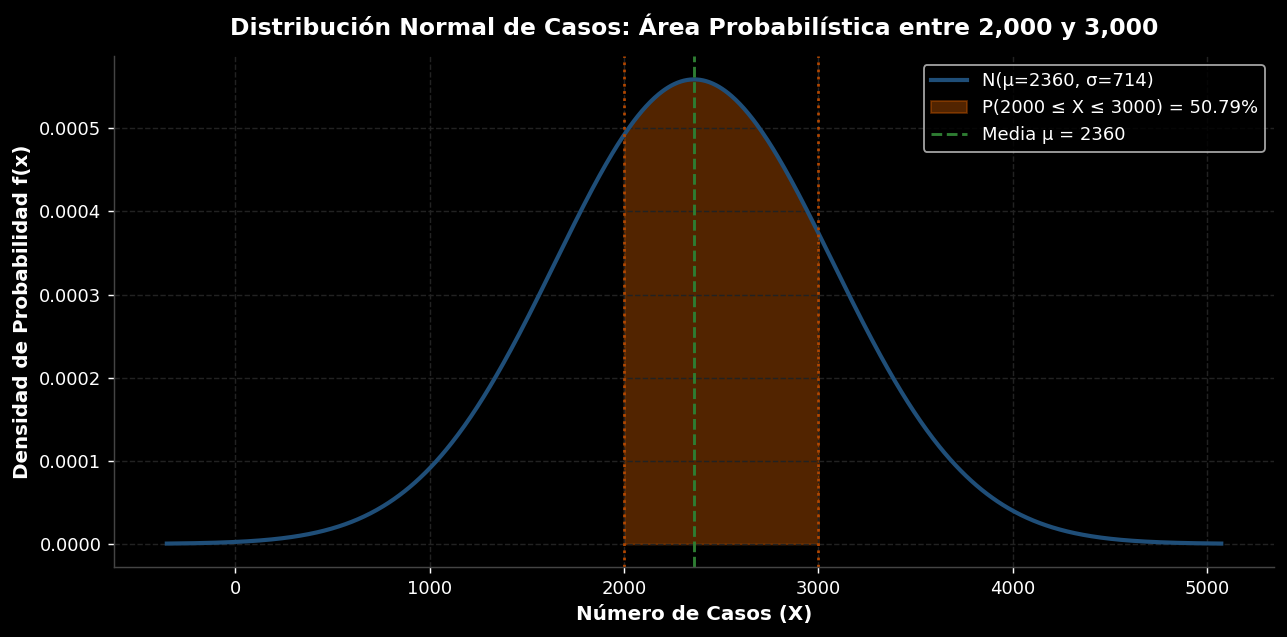

In [25]:
# Verificación computacional exacta con scipy.stats.norm
mu = 2360
sigma = 714
x1, x2 = 2000, 3000

z1 = (x1 - mu) / sigma
z2 = (x2 - mu) / sigma

phi_z1 = norm.cdf(z1)
phi_z2 = norm.cdf(z2)
prob_intervalo = norm.cdf(x2, loc=mu, scale=sigma) - norm.cdf(x1, loc=mu, scale=sigma)

print("=== RESULTADOS DE DISTRIBUCIÓN NORMAL N(2360, 714) ===")
print(f"Z1 (para X = {x1}): {z1:.4f}  -->  Φ(Z1) = {phi_z1:.6f}")
print(f"Z2 (para X = {x2}): {z2:.4f}  -->  Φ(Z2) = {phi_z2:.6f}")
print(f"P({x1} <= X <= {x2}) = {prob_intervalo:.6f} ({prob_intervalo * 100:.2f}%)")

# Visualización del área bajo la curva normal
x_vals = np.linspace(mu - 3.8 * sigma, mu + 3.8 * sigma, 1000)
y_vals = norm.pdf(x_vals, loc=mu, scale=sigma)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_vals, y_vals, color='#1F4E78', linewidth=2.3, label=f'N(μ={mu}, σ={sigma})')

x_fill = np.linspace(x1, x2, 400)
y_fill = norm.pdf(x_fill, loc=mu, scale=sigma)
ax.fill_between(x_fill, y_fill, color='#D95F02', alpha=0.38, label=f'P(2000 ≤ X ≤ 3000) = {prob_intervalo*100:.2f}%')

ax.axvline(mu, color='#2E7D32', linestyle='--', linewidth=1.6, label=f'Media μ = {mu}')
ax.axvline(x1, color='#B34700', linestyle=':', linewidth=1.5)
ax.axvline(x2, color='#B34700', linestyle=':', linewidth=1.5)

ax.set_title('Distribución Normal de Casos: Área Probabilística entre 2,000 y 3,000', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Número de Casos (X)', fontsize=11, fontweight='bold')
ax.set_ylabel('Densidad de Probabilidad f(x)', fontsize=11, fontweight='bold')
ax.legend(frameon=True, fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [26]:
# Resumen automatizado de hallazgos clave para respaldar las conclusiones
pos_total = (df['RESULTADO_ANTIGENO'] == 'Positivo').sum()
neg_total = (df['RESULTADO_ANTIGENO'] == 'Negativo').sum()
pend_total = (df['RESULTADO_ANTIGENO'] == 'Pendiente').sum()
hosp_total = (df['TIPO_PACIENTE'] == 'Hospitalizado').sum()
amb_total = (df['TIPO_PACIENTE'] == 'Ambulatorio').sum()
top_comorb = df_prob_nacional.iloc[0]
top_cond = df_prob_nacional.sort_values('P(Positivo | Comorbilidad) [Condicional]', ascending=False).iloc[0]

print("=== SÍNTESIS NUMÉRICA DE HALLAZGOS ===")
print(f"1. Universo analizado: {total_registros:,} registros epidemiológicos.")
print(f"2. Distribución diagnóstica: {pos_total:,} Positivos ({pos_total/total_registros*100:.2f}%), "
      f"{neg_total:,} Negativos ({neg_total/total_registros*100:.2f}%), "
      f"{pend_total:,} Pendientes ({pend_total/total_registros*100:.2f}%).")
print(f"3. Tipo de atención: {amb_total:,} Ambulatorios ({amb_total/total_registros*100:.2f}%) vs. "
      f"{hosp_total:,} Hospitalizados ({hosp_total/total_registros*100:.2f}%).")
print(f"4. Comorbilidad más frecuente (probabilidad simple): {top_comorb['Comorbilidad']} "
      f"con P(C) = {top_comorb['P(Comorbilidad) [Simple]']*100:.2f}%.")
print(f"5. Comorbilidad con mayor tasa condicional de positividad: {top_cond['Comorbilidad']} "
      f"con P(Positivo | C) = {top_cond['P(Positivo | Comorbilidad) [Condicional]']*100:.2f}%.")

=== SÍNTESIS NUMÉRICA DE HALLAZGOS ===
1. Universo analizado: 12,634,194 registros epidemiológicos.
2. Distribución diagnóstica: 1,774,708 Positivos (14.05%), 5,853,547 Negativos (46.33%), 5,005,939 Pendientes (39.62%).
3. Tipo de atención: 11,543,303 Ambulatorios (91.37%) vs. 1,090,891 Hospitalizados (8.63%).
4. Comorbilidad más frecuente (probabilidad simple): Hipertension con P(C) = 11.20%.
5. Comorbilidad con mayor tasa condicional de positividad: Obesidad con P(Positivo | C) = 13.75%.


## 6. Interpretación General y Conclusiones

1. **Procesamiento Eficiente de Datos Masivos:** El uso de tipado categórico (`category`) y selección explícita de columnas en `pandas` permitió procesar el **100% de los más de 12.63 millones de registros** (~1.5 GB en disco) utilizando menos de 400 MB de memoria RAM, evitando desbordamientos en Google Colab y garantizando tiempos de ejecución de pocos segundos por consulta.
2. **Comportamiento Epidemiológico y Demográfico:** La distribución etaria refleja una concentración significativa en población adulta económicamente activa (mediana alrededor de los 35–40 años), mientras que la evolución mensual evidencia claramente las distintas olas epidemiológicas ocurridas entre 2020 y 2021. Asimismo, la amplia mayoría de los pacientes recibió manejo ambulatorio frente a un porcentaje menor pero clínicamente crítico de hospitalizaciones.
3. **Impacto de las Comorbilidades (Probabilidad Simple vs. Condicional):** Las enfermedades crónico-degenerativas de mayor prevalencia en México —particularmente **hipertensión, obesidad y diabetes**— presentan las probabilidades simples $P(C_i)$ más altas dentro de la base de datos. Al evaluar la probabilidad condicional $P(\text{Positivo} \mid C_i)$ y desagregarla por entidad federativa, se observan variaciones regionales relevantes asociadas tanto a la carga epidemiológica estatal como a la cobertura de pruebas diagnósticas.
4. **Modelado Paramétrico con Distribución Normal:** Bajo el supuesto $X \sim N(\mu = 2360, \sigma = 714)$, la probabilidad de registrar entre $2000$ y $3000$ casos es de **$50.79\%$** ($P(-0.5042 \le Z \le 0.8964) = 0.5079$), lo que indica que prácticamente la mitad de las observaciones esperadas bajo este modelo se concentran dentro de dicha banda central alrededor de la media.